In [1]:
from pathlib import Path
import os
import random

import mindmap as mm

import numpy as np
import pandas as pd
import pygsp
import pyvista as pv 

In [3]:
sub = "sub-pat25"
env = mm.io.read_config("../configurations/spike.yml")

# directories
mm_dir = Path(os.environ["MM_DIR"])

# data
data = mm.io.read_dataset(sub, "src", "parc", "white", "cras")
std  = mm.io.read_standards("conn")

# parameters
cons_thresh = 40       # consistency threshold
coef        = 5       
dmax        = 0.010    # maximum distance for short distance connection

len_thresh  = 25       # fiber length threshold
n_thresh    = 20       # number of streamlines threshold

DATA SUMMARY
Dataset: spike
Subject: sub-pat25
Retrieved objects:
- parc
- src
- white
- cras
Missing objects:


In [12]:
def correct_labels(labels, sources, parcel):
    """
    Correct labels that misplace left and right hemisphere dipoles because the parcellation is not perfect.
    """
    # map to switch from label id to label name
    clut = parcel.get_clut()
    map  = pd.Series(clut["Label name"].values, index=clut["#No."]).to_dict()
    
    label_names = [map[id] for id in labels]

    # left/right hemisphere seperation
    split = len(sources[0]["vertno"])

    # switch 'lh' labels in right hemisphere to 'rh' homologue and vice virsa
    label_names[:split] = [l.replace("-rh-", "-lh-") for l in label_names[:split]]
    label_names[split:] = [l.replace("-lh-", "-rh-") for l in label_names[split:]]

    # convert back to lable ids
    new_labels = [list(map.keys())[list(map.values()).index(n)] for n in label_names]

    return new_labels

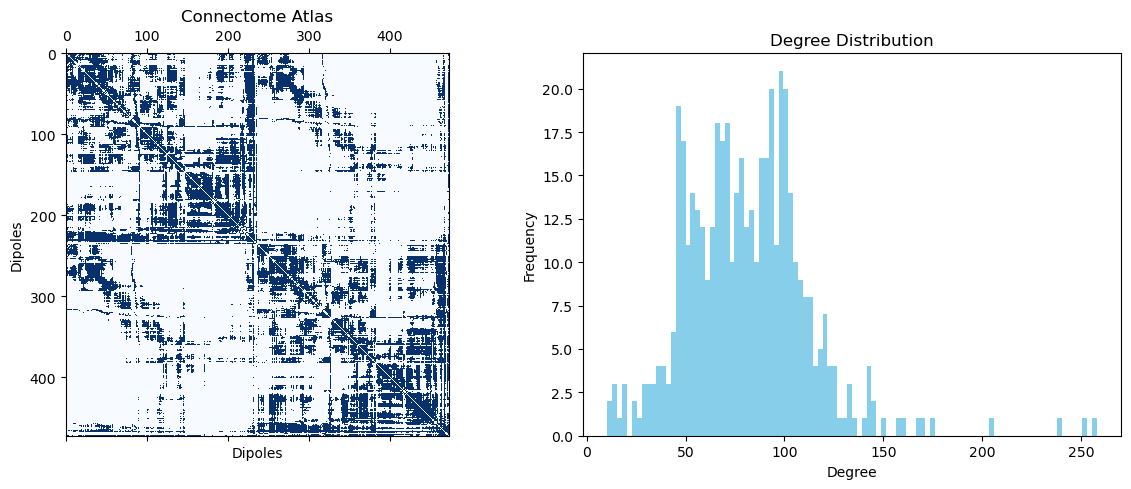

In [13]:
# label sources
pos    = mm.utils.get_src_position(data["src"])
pos    = pos*1000 + data["cras"]                   # in surface RAS space in [mm].  !!!!!!! Add the cras translation now that I now  !!!!!!!
labels = data["parc"].label_points(pos, id=True)   # brain region label for each source.

# some left/right regions are very close and get mixed up
labels = correct_labels(labels, data["src"], data["parc"])

# convert atlas to binary adjacency matrix
consistency = std["conn"]["matrices"]["consistency"]
number      = std["conn"]["matrices"]["numbStlines"]

# convert atlas to binary adjacency matrix
consistency = std["conn"]["matrices"]["consistency"]
length      = std["conn"]["matrices"]["length"]
number      = std["conn"]["matrices"]["numbStlines"]

regions = std["conn"]["header"]["gmcoords"][:]

sc_atlas = np.bitwise_and(
    consistency[:,:] > cons_thresh, 
    length[:,:] > len_thresh,
    number[:,:] > n_thresh,
)
sc_atlas = number * sc_atlas
sc_atlas = np.nan_to_num(sc_atlas)

mm.viz.plot_connectome(np.log((sc_atlas>0)+1), name="Connectome Atlas")

In [ ]:
regions = std["conn"]["header"]["gmcoords"][:]

plotter = pv.Plotter()
plotter.add_mesh(pv.PolyData(regions), render_points_as_spheres=True, point_size=10, color="#0A2463")

for i in range(len(sc_atlas)):
    for j in range(i, len(sc_atlas)):
        if (sc_atlas[i,j] > 100) & (sc_atlas[i,j] < 200):
            plotter.add_mesh(pv.Line(regions[i], regions[j]), line_width=1, color="#3E92CC")

plotter.show()

In [14]:
G = pygsp.graphs.Graph(sc_atlas, lap_type="normalized", coords=regions)
G.compute_fourier_basis()

cst = G.U.T

In [23]:
labs   = std["conn"]["header"]["gmcodes"][:]
signal = cst[470,:][np.array(labels)-1]

max_abs = np.max(np.abs(signal))
mm.viz.plot_brain_signal(data["src"], signal, cmap="RdBu", clim=[-max_abs, max_abs]).show()

Widget(value='<iframe src="http://localhost:36551/index.html?ui=P_0x788275c52e10_8&reconnect=auto" class="pyvi…

In [19]:
labs.shape

(473,)

# Plot example BEM

Using surface: /home/nino/mne_data/MNE-sample-data/subjects/sample/bem/inner_skull.surf
Using surface: /home/nino/mne_data/MNE-sample-data/subjects/sample/bem/outer_skull.surf
Using surface: /home/nino/mne_data/MNE-sample-data/subjects/sample/bem/outer_skin.surf


/home/nino/miniconda3/envs/mindmap/lib/python3.12/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


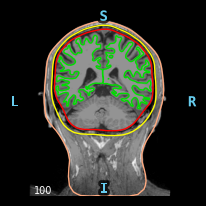

In [9]:
import mne 
from mne.datasets import sample

data_path = sample.data_path()

# the raw file containing the cahnnel location + types
sample_dir = data_path / "MEG" / "sample" 
raw_fname = sample_dir / "sample_audvis_raw.fif" 

subjects_dir = data_path / "subjects" 
subject = "sample" 


plot_bem_kwargs = dict(
    subject = subject,
    subjects_dir = subjects_dir,
    brain_surfaces = "white",
    orientation = "coronal",
    slices = [100],
)

mne.viz.plot_bem(**plot_bem_kwargs)